# Case 1: Whom should the bank call?

**Applies chapters 1, 2 and 3:** prediction, rule or query; input, target, prediction time; train, validation, test, the seed and the baseline.

A Portuguese bank phoned 41,188 clients between May 2008 and November 2010 to sell a term deposit (money locked away for a fixed time at a fixed rate). Every call costs an agent's minutes, and most clients say no. The marketing team wants a list: whom do we call first?

By the end of this notebook you can:

- say why "whom do we call" is a prediction problem and name its input, target and prediction time;
- pick the columns the bank knows on the morning of the call;
- split the rows into train, validation and test with a stated seed, and seal the test slice.

**Search terms:** problem framing in machine learning, features and labels, train validation test split, stratified split, random seed.

| | The bank (real data) | Kalpa Retail (our decision) |
|---|---|---|
| The action | a phone call from an agent | a Rs 40 discount nudge from Marketing |
| The question | will this client open a term deposit? | will this member buy again in the next ninety days? |
| The input | the client table on the morning of the call | the customer table on the day of the nudge |
| The target | `y`: yes or no, known once the call ends | the repeat flag, known ninety days later |
| Who asks | the campaign manager | Marketing, with Kavya Nair (senior analyst) asking for the baseline first |

In [1]:
# Tools for this notebook, and one helper that prints a check as PASS or FAIL.
import io, zipfile, pathlib, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

def check(label, ok):
    print(("PASS  " if ok else "FAIL  ") + label)

In [2]:
# Load the day's public dataset once; later runs read the cached copy.
CACHE = pathlib.Path.home() / ".cache" / "c2_datasets"
CACHE.mkdir(parents=True, exist_ok=True)

def load_bank():
    """UCI Bank Marketing, bank-additional-full.csv (CC BY 4.0), cached after the first download."""
    f = CACHE / "bank-additional-full.csv"
    if not f.exists():
        url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
        outer = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url, timeout=60).read()))
        inner = zipfile.ZipFile(io.BytesIO(outer.read("bank-additional.zip")))
        f.write_bytes(inner.read("bank-additional/bank-additional-full.csv"))
    return pd.read_csv(f, sep=";")

bank = load_bank()
print(bank.shape)

(41188, 21)


## How many clients said yes?

The target column is `y`. Before you count it, commit to a guess.

**Predict before you run.** What share of the 41,188 calls ended in a yes? (a) about half (b) about a quarter (c) about one in nine (d) about one in thirty

In [3]:
# Count the target: how many yes, how many no, and the share of yes.
counts = bank["y"].value_counts()
rate = (bank["y"] == "yes").mean()
print(counts.to_string())
print(f"Share of yes: {rate:.4f}, which is about 1 in {1/rate:.1f} calls")

y
no     36548
yes     4640
Share of yes: 0.1127, which is about 1 in 8.9 calls


**What happened.** The answer is (c): 4,640 yes against 36,548 no, a share of 0.1127. Nine calls in ten end in a no, and every later number today is read against that fact.

## Which columns does the bank know on the morning of the call?

Chapter 2's test is one question asked of every column: on the morning of the call, before anyone dials, does the bank already hold this value? Today the model uses only the client's profile and how earlier campaigns went. Seven more columns arrive from other feeds, and Wednesday audits each of them with the same question, so they wait.

In [4]:
# Sort the 21 columns into the three groups the week works with.
PROFILE = ["age", "job", "marital", "education", "default", "housing", "loan"]
HISTORY = ["contact", "month", "day_of_week", "campaign", "previous", "poutcome"]
TARGET = ["y"]
LATER = [c for c in bank.columns if c not in PROFILE + HISTORY + TARGET]

groups = pd.DataFrame({
    "group": ["profile (used today)", "history (used today)", "other feeds (audited Wednesday)", "target"],
    "columns": [", ".join(PROFILE), ", ".join(HISTORY), ", ".join(LATER), "y"],
    "count": [len(PROFILE), len(HISTORY), len(LATER), 1],
})
print(groups.to_string(index=False))
check("the four groups hold all 21 columns once each", groups["count"].sum() == bank.shape[1])
check("today's input has 13 columns", len(PROFILE + HISTORY) == 13)

                          group                                                                              columns  count
           profile (used today)                                 age, job, marital, education, default, housing, loan      7
           history (used today)                            contact, month, day_of_week, campaign, previous, poutcome      6
other feeds (audited Wednesday) duration, pdays, emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m, nr.employed      7
                         target                                                                                    y      1
PASS  the four groups hold all 21 columns once each
PASS  today's input has 13 columns


## Where does the prediction sit in time?

The prediction is made on the morning of the call. Everything to the left of that moment can be an input; the answer, `y`, only exists to the right of it. This one picture comes back every day this week, and each day adds to it.

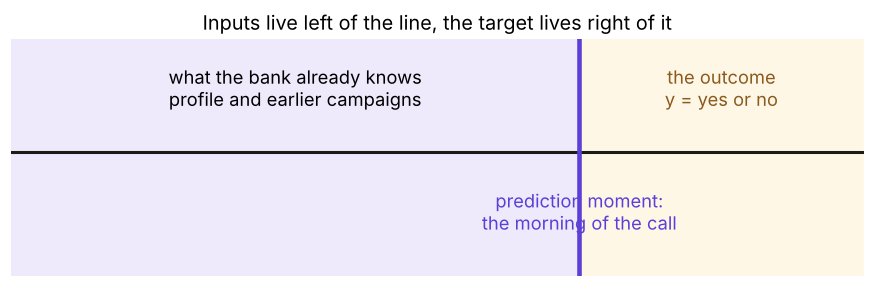

In [5]:
# The week's timeline picture, in its Monday state.
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.axhline(0, color="#1C1B16", lw=2)
ax.axvspan(0, 6, color="#EEEAFB")
ax.axvspan(6, 9, color="#FFF7E6")
ax.axvline(6, color="#5B3FD6", lw=3)
ax.text(3, 0.45, "what the bank already knows\nprofile and earlier campaigns", ha="center", fontsize=12)
ax.text(6, -0.75, "prediction moment:\nthe morning of the call", ha="center", fontsize=12, color="#5B3FD6")
ax.text(7.5, 0.45, "the outcome\ny = yes or no", ha="center", fontsize=12, color="#8A5A1F")
ax.set_xlim(0, 9); ax.set_ylim(-1.2, 1.1); ax.axis("off")
ax.set_title("Inputs live left of the line, the target lives right of it", fontsize=13)
plt.show()

## How do we split the rows so a score means something?

The week uses one split. The test slice is cut first, 20 percent of rows, and sealed: nobody scores a model on it until Friday. The rest splits 75 to 25 into train (the model learns here) and validation (we compare models here). `stratify` keeps the share of yes the same in every slice, and `random_state=42` is the seed that makes the cut the same on every laptop.

**Predict before you run.** How many rows land in validation? (a) 8,238 (b) 10,297 (c) 24,712 (d) 32,950

In [6]:
# The week's pipeline: the same columns, the same split and the same model every day.
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# The customer table on the morning of the call: who the client is and how earlier campaigns went.
PROFILE = ["age", "job", "marital", "education", "default", "housing", "loan"]
HISTORY = ["contact", "month", "day_of_week", "campaign", "previous", "poutcome"]
COLUMNS = PROFILE + HISTORY

def week_split(df, seed=42):
    """Test is sealed first (20 percent, the envelope); the rest splits 75/25 into train and validation."""
    y = (df["y"] == "yes").astype(int)
    rest, test = train_test_split(df.index, test_size=0.20, stratify=y, random_state=seed)
    train, val = train_test_split(rest, test_size=0.25, stratify=y.loc[rest], random_state=seed)
    return df.loc[train], df.loc[val], df.loc[test]

def logistic(columns, df):
    # pandas 3 reads text as the "str" dtype, so test for numbers rather than for object.
    num = [c for c in columns if pd.api.types.is_numeric_dtype(df[c])]
    cat = [c for c in columns if c not in num]
    prep = ColumnTransformer([("num", StandardScaler(), num),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    return Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=2000))])

train, val, test = week_split(bank, seed=42)
for name, part in [("train", train), ("validation", val), ("test (sealed)", test)]:
    print(f"{name:14s} {len(part):6,d} rows   share of yes {(part['y'] == 'yes').mean():.4f}")

train          24,712 rows   share of yes 0.1127
validation      8,238 rows   share of yes 0.1126
test (sealed)   8,238 rows   share of yes 0.1126


**What happened.** The answer is (a): 8,238 rows in validation and 8,238 sealed in test, with 24,712 left to train on. The share of yes is 0.1126 or 0.1127 in every slice because the split was stratified.

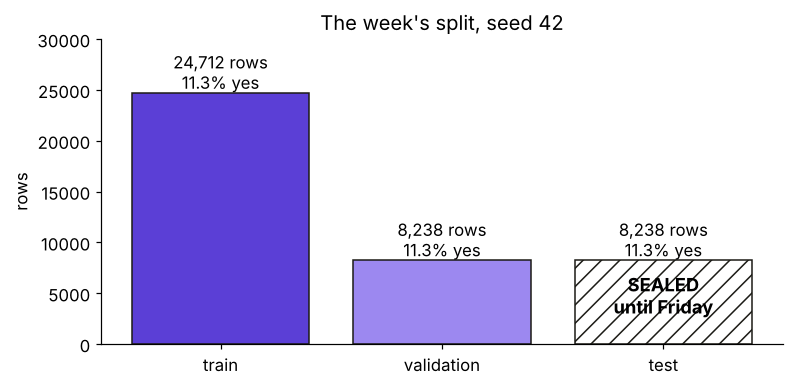

PASS  the three slices add up to every row
PASS  no row sits in two slices
PASS  the share of yes matches across slices within 0.1 point


In [7]:
# Picture the split: three slices, the same share of yes, one of them sealed.
sizes = [len(train), len(val), len(test)]
shares = [(p["y"] == "yes").mean() for p in (train, val, test)]
fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.bar(["train", "validation", "test"], sizes, color=["#5B3FD6", "#9C88F0", "#FFFFFF"],
              edgecolor="#1C1B16", hatch=["", "", "//"])
for b, n, s in zip(bars, sizes, shares):
    ax.text(b.get_x() + b.get_width() / 2, n + 400, f"{n:,} rows\n{s:.1%} yes", ha="center", fontsize=11)
ax.text(2, 3000, "SEALED\nuntil Friday", ha="center", fontsize=12, fontweight="bold")
ax.set_ylim(0, 30000); ax.set_ylabel("rows")
ax.set_title("The week's split, seed 42")
plt.show()

check("the three slices add up to every row", sum(sizes) == len(bank))
check("no row sits in two slices", len(set(train.index) & set(val.index)) + len(set(val.index) & set(test.index)) + len(set(train.index) & set(test.index)) == 0)
check("the share of yes matches across slices within 0.1 point", max(shares) - min(shares) < 0.001)

## The trap: a split with no seed

A hurried analyst writes `train_test_split(bank, test_size=0.2)` with no seed and no stratify. The code runs, so it looks fine. Run it five times and the validation share of yes moves, which means the baseline you have to beat moves too, and two teammates quoting "the validation score" are quoting scores on different rows.

In [8]:
# Five unseeded, unstratified splits: the share of yes in the held-out part moves each time.
from sklearn.model_selection import train_test_split
rng_shares = []
for _ in range(5):
    _, held = train_test_split(bank, test_size=0.2)
    rng_shares.append((held["y"] == "yes").mean())
print("held-out share of yes, five runs without a seed:", [round(float(s), 4) for s in rng_shares])

seeded = [(week_split(bank, seed=42)[1]["y"] == "yes").mean() for _ in range(5)]
print("validation share of yes, five runs with seed 42:  ", [round(float(s), 4) for s in seeded])
check("seed 42 gives the identical slice every run", len(set(seeded)) == 1)

held-out share of yes, five runs without a seed: [0.113, 0.1133, 0.1148, 0.1126, 0.1126]


validation share of yes, five runs with seed 42:   [0.1126, 0.1126, 0.1126, 0.1126, 0.1126]
PASS  seed 42 gives the identical slice every run


**The fix.** State the seed, stratify on the target, and write both into the notebook's first cells, so anybody who reruns it gets the same rows and the same baseline.

## What did this notebook establish?

| Question | Answer |
|---|---|
| Is "whom do we call" a prediction problem? | Yes: an input known on the morning of the call, a target known after it, and a call list that changes with the score |
| What share said yes? | 4,640 of 41,188, which is 0.1127 |
| What is the input today? | 13 columns: 7 about the client, 6 about this and earlier campaigns |
| How are the rows split? | train 24,712, validation 8,238, test 8,238 sealed until Friday, seed 42, stratified |
| What does the seed buy? | the same rows, so the same baseline, on every laptop |

**Next:** case 2 scores the dumbest possible model on the validation slice and asks the logistic model to beat it.